# 🦟 Capstone · Malaria Cell Classifier

**Patient-level ResNet-18 · hardened inference · research demo only**

| | |
|---|---|
| **Task** | Binary classification of single RBC crops (parasitized / uninfected) |
| **Data** | NIH/NLM thin-smear collection · CC BY 4.0 · no personal data |
| **Split** | Patient-grouped 70 / 15 / 15 — no patient leakage |
| **Stack** | ResNet-18 · safetensors · Gradio demo · upload validator |

> ⚠️ **Not a diagnostic tool.** Confident scores can still be wrong.


## 0 · Setup


In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
!pip -q install kagglehub safetensors gradio plotly scikit-learn


In [3]:
import os, random, re, io, json, hashlib, warnings, time, gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18
from torchvision.transforms import v2

from sklearn.model_selection import train_test_split, GroupKFold, cross_val_predict
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, f1_score,
    confusion_matrix, precision_recall_curve, average_precision_score,
)

# ── style ────────────────────────────────────────────────
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#fafafa",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})
PLOTLY_TEMPLATE = "plotly_white"

SEED = 42
IMG  = 128
MEAN = (0.485, 0.456, 0.406)
STD  = (0.229, 0.224, 0.225)
BASE = Path("/content/drive/MyDrive/malaria")
ART  = BASE / "repo_artifacts"
BASE.mkdir(parents=True, exist_ok=True)
ART.mkdir(parents=True, exist_ok=True)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__}  ·  device: {device}")


torch 2.11.0+cu130  ·  device: cuda


## 1 · Data

Download the public NIH/NLM collection, remove the exact duplicates the archive contains, and extract patient IDs from filenames.


In [4]:
import kagglehub
raw_path = Path(kagglehub.dataset_download("iarunava/cell-images-for-detecting-malaria"))
print("downloaded →", raw_path)


Using Colab cache for faster access to the 'cell-images-for-detecting-malaria' dataset.
downloaded → /kaggle/input/cell-images-for-detecting-malaria


In [5]:
rows = []
for p in raw_path.rglob("*.png"):
    if p.parent.name in ("Parasitized", "Uninfected"):
        rows.append({
            "path":  str(p),
            "fname": p.name,
            "label": 1 if p.parent.name == "Parasitized" else 0,
        })
df = (pd.DataFrame(rows)
        .sort_values("path")
        .drop_duplicates("fname")
        .reset_index(drop=True))

df["patient_id"] = df.fname.str.extract(r"^(C\d+(?:P\d+)?)", expand=False)
df["image_id"]   = df.fname.str.replace(r"_cell_\d+\.png$", "", regex=True)
assert df.patient_id.notna().all()

print(f"{len(df):,} unique crops  ·  {df.patient_id.nunique()} patients")


27,558 unique crops  ·  200 patients


In [6]:
# Image geometry
def img_meta(p):
    with Image.open(p) as im:
        im.load()
        return im.width, im.height, im.mode

meta = df.path.map(img_meta)
df[["w", "h", "mode"]] = pd.DataFrame(meta.tolist(), index=df.index)
df["aspect"] = df.w / df.h

pat = (df.groupby("patient_id")
         .agg(n=("label", "size"), n_para=("label", "sum"))
         .assign(infected=lambda x: x.n_para > 0,
                 frac_para=lambda x: x.n_para / x.n))


### Interactive overview


In [7]:
# ── label balance + patient infection status ──
fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=("Cell labels", "Patients by status", "Cells per patient"),
    specs=[[{"type": "domain"}, {"type": "domain"}, {"type": "histogram"}]],
)

lab_counts = df.label.value_counts().sort_index()
fig.add_trace(go.Pie(
    labels=["Uninfected", "Parasitized"], values=lab_counts.values,
    marker_colors=["#4CAF50", "#E53935"], hole=0.45,
    textinfo="label+value", showlegend=False,
), row=1, col=1)

inf_counts = pat.infected.value_counts()
fig.add_trace(go.Pie(
    labels=["Healthy", "Infected"], values=[inf_counts.get(False, 0), inf_counts.get(True, 0)],
    marker_colors=["#66BB6A", "#EF5350"], hole=0.45,
    textinfo="label+value", showlegend=False,
), row=1, col=2)

fig.add_trace(go.Histogram(
    x=pat["n"], nbinsx=30, marker_color="#5C6BC0",
    name="cells / patient",
), row=1, col=3)

fig.update_layout(
    template=PLOTLY_TEMPLATE, height=340, margin=dict(t=50, b=30),
    title_text="Dataset at a glance",
)
fig.update_xaxes(title_text="cells per patient", row=1, col=3)
fig.show()

print(f"patients infected / healthy: {pat.infected.sum()} / {(~pat.infected).sum()}")
print(f"cells per patient — median {pat.n.median():.0f}, max {pat.n.max()}")


patients infected / healthy: 150 / 50
cells per patient — median 86, max 702


In [8]:
# ── size distribution by label ──
fig = px.scatter(
    df.sample(min(4000, len(df)), random_state=SEED),
    x="w", y="h", color=df.loc[df.sample(min(4000, len(df)), random_state=SEED).index, "label"].map({0: "Uninfected", 1: "Parasitized"}),
    color_discrete_map={"Uninfected": "#4CAF50", "Parasitized": "#E53935"},
    opacity=0.35, template=PLOTLY_TEMPLATE,
    title="Image size by label (sample of 4 000)",
    labels={"w": "width (px)", "h": "height (px)", "color": ""},
)
fig.update_layout(height=400, legend=dict(orientation="h", y=1.08))
fig.show()


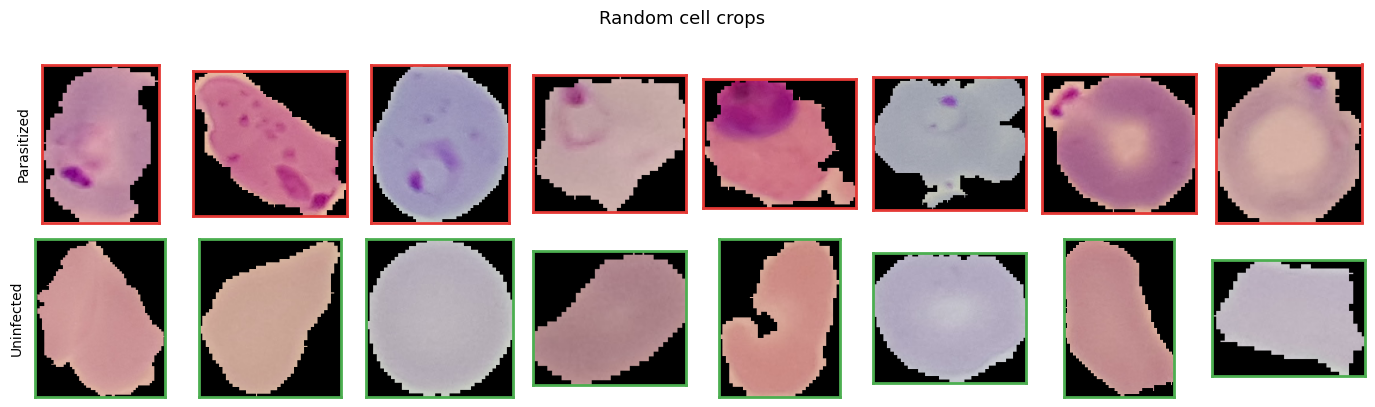

In [9]:
# ── sample grid ──
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for row, (lab, name) in enumerate([(1, "Parasitized"), (0, "Uninfected")]):
    sample = df[df.label == lab].sample(8, random_state=SEED)
    for ax, (_, r) in zip(axes[row], sample.iterrows()):
        ax.imshow(Image.open(r.path))
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_color("#E53935" if lab else "#4CAF50")
            spine.set_linewidth(2)
    axes[row, 0].set_ylabel(name, fontsize=10, rotation=90, labelpad=8)
plt.suptitle("Random cell crops", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()


## 2 · Leakage Probe

Does image size alone predict the label?  
Under a **random** split the answer is yes; under a **patient-grouped** split the signal collapses. Patient identity is a confounder → we must split by patient.


In [10]:
X = df[["w", "h", "aspect"]].values
y = df.label.values
g = df.patient_id.values
clf = HistGradientBoostingClassifier(random_state=SEED, max_iter=50)

results = {}
for name, cv in [("Random 5-fold", None), ("Patient GroupKFold", GroupKFold(5))]:
    if cv is None:
        from sklearn.model_selection import KFold
        cv = KFold(5, shuffle=True, random_state=SEED)
    p = cross_val_predict(clf, X, y, cv=cv, groups=g, method="predict_proba")[:, 1]
    results[name] = roc_auc_score(y, p)

fig = go.Figure(go.Bar(
    x=list(results.keys()), y=list(results.values()),
    marker_color=["#EF5350", "#42A5F5"],
    text=[f"{v:.3f}" for v in results.values()], textposition="outside",
))
fig.update_layout(
    template=PLOTLY_TEMPLATE, title="AUC from image size alone",
    yaxis=dict(title="AUC", range=[0.4, 0.85]), height=350,
    margin=dict(t=50, b=30),
)
fig.show()
print({k: f"{v:.3f}" for k, v in results.items()})


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:86: UserWarning:

The groups parameter is ignored by KFold



{'Random 5-fold': '0.541', 'Patient GroupKFold': '0.534'}


## 3 · Patient-Level Split

Stratify on *infected vs healthy patient*, then assign **whole patients** to train / val / test (≈70 / 15 / 15).


In [11]:
pat_df = (df.groupby("patient_id")
            .agg(infected=("label", lambda s: s.sum() > 0))
            .reset_index())

trv_ids, test_ids = train_test_split(
    pat_df["patient_id"], test_size=0.15,
    stratify=pat_df["infected"], random_state=SEED)
tr_ids, val_ids = train_test_split(
    trv_ids, test_size=0.176,
    stratify=pat_df.set_index("patient_id").loc[trv_ids, "infected"],
    random_state=SEED)

split_map = {**{p: "train" for p in tr_ids},
             **{p: "val"   for p in val_ids},
             **{p: "test"  for p in test_ids}}
df["split"] = df.patient_id.map(split_map)
assert df.groupby("patient_id")["split"].nunique().eq(1).all()

summary = (df.groupby("split")
             .agg(patients=("patient_id", "nunique"),
                  cells=("label", "size"),
                  para=("label", "sum"))
             .reindex(["train", "val", "test"]))
summary["para_pct"] = (summary.para / summary.cells * 100).round(1)


In [12]:
fig = make_subplots(rows=1, cols=2, subplot_titles=("Patients per split", "Cells per split"))

fig.add_trace(go.Bar(
    x=summary.index, y=summary.patients, name="patients",
    marker_color="#5C6BC0", text=summary.patients, textposition="outside",
), row=1, col=1)

fig.add_trace(go.Bar(
    x=summary.index, y=summary.cells - summary.para, name="uninfected",
    marker_color="#66BB6A",
), row=1, col=2)
fig.add_trace(go.Bar(
    x=summary.index, y=summary.para, name="parasitized",
    marker_color="#EF5350",
), row=1, col=2)

fig.update_layout(
    template=PLOTLY_TEMPLATE, barmode="stack", height=360,
    title_text="Patient-level split", legend=dict(orientation="h", y=1.12),
)
fig.show()
summary


,patients,cells,para,para_pct
split,,,,
train,140,20195,10521,52.1
val,30,3843,1786,46.5
test,30,3520,1472,41.8


## 4 · Dataset & Loaders


In [13]:
class CellDS(Dataset):
    def __init__(self, frame, tfm):
        self.paths  = frame["path"].tolist()
        self.labels = frame["label"].astype(np.float32).tolist()
        self.tfm    = tfm
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.tfm(img), self.labels[i]

train_tf = v2.Compose([
    v2.Resize((IMG, IMG)),
    v2.RandomHorizontalFlip(), v2.RandomVerticalFlip(),
    v2.ColorJitter(0.1, 0.1, 0.1),
    v2.ToImage(), v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])
eval_tf = v2.Compose([
    v2.Resize((IMG, IMG)),
    v2.ToImage(), v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])

splits = {s: df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test")}
loaders = {
    "train": DataLoader(CellDS(splits["train"], train_tf), batch_size=64,  shuffle=True,  num_workers=2, pin_memory=True),
    "val":   DataLoader(CellDS(splits["val"],   eval_tf),  batch_size=128, shuffle=False, num_workers=2, pin_memory=True),
    "test":  DataLoader(CellDS(splits["test"],  eval_tf),  batch_size=128, shuffle=False, num_workers=2, pin_memory=True),
}
print({k: len(v.dataset) for k, v in loaders.items()})


{'train': 20195, 'val': 3843, 'test': 3520}


## 5 · Colour Baseline

Mean RGB of non-background pixels + background fraction → HistGradientBoosting.  
A cheap floor that the CNN must beat.


In [14]:
def colour_feats(path):
    a = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32)
    mask = a.max(axis=2) > 10
    if mask.sum() == 0:
        return [0., 0., 0., 1.]
    return [*a[mask].mean(0), 1 - mask.mean()]

feats = np.array([colour_feats(p) for p in df.path])
df[["R", "G", "B", "bg_frac"]] = feats

Xtr = df.loc[df.split == "train", ["R", "G", "B", "bg_frac"]]
ytr = df.loc[df.split == "train", "label"]
Xte = df.loc[df.split == "test",  ["R", "G", "B", "bg_frac"]]
yte = df.loc[df.split == "test",  "label"]

hgb = HistGradientBoostingClassifier(random_state=SEED).fit(Xtr, ytr)
p_hgb = hgb.predict_proba(Xte)[:, 1]
print(f"HGB colour baseline  AUC = {roc_auc_score(yte, p_hgb):.3f}")


HGB colour baseline  AUC = 0.670


In [15]:
# Interactive colour space
sample = df.sample(min(3000, len(df)), random_state=SEED)
fig = px.scatter_3d(
    sample, x="R", y="G", z="B",
    color=sample.label.map({0: "Uninfected", 1: "Parasitized"}),
    color_discrete_map={"Uninfected": "#4CAF50", "Parasitized": "#E53935"},
    opacity=0.4, template=PLOTLY_TEMPLATE,
    title="Mean cell colour (RGB) — click & drag to rotate",
    labels={"R": "Red", "G": "Green", "B": "Blue"},
)
fig.update_traces(marker_size=2)
fig.update_layout(height=480, legend=dict(orientation="h", y=1.05))
fig.show()


## 6 · ResNet-18

ImageNet init → single logit. AdamW + cosine schedule; keep the best validation-AUC checkpoint.


In [16]:
def make_model():
    m = resnet18(weights="IMAGENET1K_V1")
    m.fc = nn.Linear(m.fc.in_features, 1)
    return m.to(device)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs = []
    for x, _ in loader:
        p = torch.sigmoid(model(x.to(device)).squeeze(1))
        probs.append(p.cpu())
    return torch.cat(probs).numpy()

def metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return {
        "AUC":  round(float(roc_auc_score(y, p)), 4),
        "Acc":  round(float(accuracy_score(y, pred)), 4),
        "F1":   round(float(f1_score(y, pred)), 4),
    }


In [17]:
def train_one(epochs=8, lr=3e-4, wd=1e-4, tag="base"):
    set_seed()
    model = make_model()
    opt   = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.BCEWithLogitsLoss()
    best_auc, best_state = 0.0, None
    history = []

    for ep in range(1, epochs + 1):
        model.train()
        t0, running = time.time(), 0.0
        for x, y in loaders["train"]:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = loss_fn(model(x).squeeze(1), y)
            loss.backward(); opt.step()
            running += loss.item() * len(y)
        sched.step()
        train_loss = running / len(loaders["train"].dataset)

        pv = predict(model, loaders["val"])
        auc = float(roc_auc_score(splits["val"].label, pv))
        history.append({"ep": ep, "train_loss": train_loss, "val_auc": auc,
                        "sec": round(time.time() - t0, 1)})
        print(f"  ep {ep}/{epochs}  loss {train_loss:.4f}  val AUC {auc:.4f}  ({history[-1]['sec']}s)")
        if auc > best_auc:
            best_auc = auc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    ckpt = BASE / f"resnet18_{tag}.pt"
    torch.save(best_state, ckpt)
    print(f"best val AUC {best_auc:.4f} → {ckpt.name}")
    return model, pd.DataFrame(history)

model, hist = train_one()


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 179MB/s]


  ep 1/8  loss 0.1296  val AUC 0.9907  (66.3s)
  ep 2/8  loss 0.0969  val AUC 0.9910  (63.5s)
  ep 3/8  loss 0.0860  val AUC 0.9912  (64.2s)
  ep 4/8  loss 0.0730  val AUC 0.9918  (64.6s)
  ep 5/8  loss 0.0656  val AUC 0.9923  (64.9s)
  ep 6/8  loss 0.0565  val AUC 0.9931  (64.7s)
  ep 7/8  loss 0.0444  val AUC 0.9941  (64.2s)
  ep 8/8  loss 0.0362  val AUC 0.9939  (64.7s)
best val AUC 0.9941 → resnet18_base.pt


In [18]:
# Interactive training curves
fig = make_subplots(rows=1, cols=2, subplot_titles=("Training loss", "Validation AUC"))

fig.add_trace(go.Scatter(
    x=hist.ep, y=hist.train_loss, mode="lines+markers",
    name="train loss", line=dict(color="#5C6BC0", width=2),
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=hist.ep, y=hist.val_auc, mode="lines+markers",
    name="val AUC", line=dict(color="#E53935", width=2),
), row=1, col=2)

fig.update_layout(template=PLOTLY_TEMPLATE, height=360, showlegend=False,
                  title_text="Training dynamics")
fig.update_xaxes(title_text="epoch")
fig.show()


## 7 · Evaluation on Held-Out Patients

Cell-level metrics, ROC / PR curves, interactive confusion-matrix heatmap, and the most confident errors.


In [19]:
pt = predict(model, loaders["test"])
yt = splits["test"].label.values
m_cnn = metrics(yt, pt)
m_hgb = metrics(yte.values, p_hgb)

print("ResNet-18 ", m_cnn)
print("HGB colour", m_hgb)


ResNet-18  {'AUC': 0.9959, 'Acc': 0.9724, 'F1': 0.967}
HGB colour {'AUC': 0.6703, 'Acc': 0.6438, 'F1': 0.541}


In [20]:
# ── ROC + PR curves (interactive) ──
fpr, tpr, _ = roc_curve(yt, pt)
prec, rec, _ = precision_recall_curve(yt, pt)
ap = average_precision_score(yt, pt)

fpr_h, tpr_h, _ = roc_curve(yte, p_hgb)
prec_h, rec_h, _ = precision_recall_curve(yte, p_hgb)
ap_h = average_precision_score(yte, p_hgb)

fig = make_subplots(rows=1, cols=2, subplot_titles=(
    f"ROC  (AUC CNN={m_cnn['AUC']:.3f})",
    f"Precision-Recall  (AP CNN={ap:.3f})",
))

fig.add_trace(go.Scatter(x=fpr, y=tpr, name="ResNet-18",
                         line=dict(color="#E53935", width=2)), row=1, col=1)
fig.add_trace(go.Scatter(x=fpr_h, y=tpr_h, name="HGB colour",
                         line=dict(color="#42A5F5", width=2, dash="dash")), row=1, col=1)
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], showlegend=False,
                         line=dict(color="gray", width=1, dash="dot")), row=1, col=1)

fig.add_trace(go.Scatter(x=rec, y=prec, name="ResNet-18",
                         line=dict(color="#E53935", width=2), showlegend=False), row=1, col=2)
fig.add_trace(go.Scatter(x=rec_h, y=prec_h, name="HGB colour",
                         line=dict(color="#42A5F5", width=2, dash="dash"), showlegend=False), row=1, col=2)

fig.update_layout(template=PLOTLY_TEMPLATE, height=400,
                  legend=dict(orientation="h", y=1.14),
                  title_text="Ranking quality on test patients")
fig.update_xaxes(title_text="FPR", row=1, col=1)
fig.update_yaxes(title_text="TPR", row=1, col=1)
fig.update_xaxes(title_text="Recall", row=1, col=2)
fig.update_yaxes(title_text="Precision", row=1, col=2)
fig.show()


In [21]:
# ── Interactive confusion-matrix heatmap ──
cm = confusion_matrix(yt, (pt >= 0.5).astype(int))
labels = ["Uninfected", "Parasitized"]

fig = go.Figure(go.Heatmap(
    z=cm, x=labels, y=labels,
    text=cm, texttemplate="%{text}", textfont_size=18,
    colorscale="Reds", showscale=False,
    hovertemplate="True: %{y}<br>Pred: %{x}<br>Count: %{z}<extra></extra>",
))
fig.update_layout(
    template=PLOTLY_TEMPLATE, height=380, width=420,
    title="Confusion matrix (threshold 0.5)",
    xaxis_title="Predicted", yaxis_title="Actual",
    yaxis=dict(autorange="reversed"),
)
fig.show()


In [22]:
# ── Score distribution ──
test_df = splits["test"].assign(prob=pt, pred=(pt >= 0.5).astype(int))
test_df["err"] = test_df.pred != test_df.label

fig = go.Figure()
for lab, name, color in [(0, "Uninfected", "#4CAF50"), (1, "Parasitized", "#E53935")]:
    fig.add_trace(go.Histogram(
        x=test_df.loc[test_df.label == lab, "prob"],
        name=name, opacity=0.65, marker_color=color, nbinsx=40,
    ))
fig.add_vline(x=0.5, line_dash="dash", line_color="gray",
              annotation_text="threshold", annotation_position="top")
fig.update_layout(
    template=PLOTLY_TEMPLATE, barmode="overlay", height=380,
    title="Predicted P(parasitized) on test set",
    xaxis_title="P(parasitized)", yaxis_title="count",
    legend=dict(orientation="h", y=1.08),
)
fig.show()


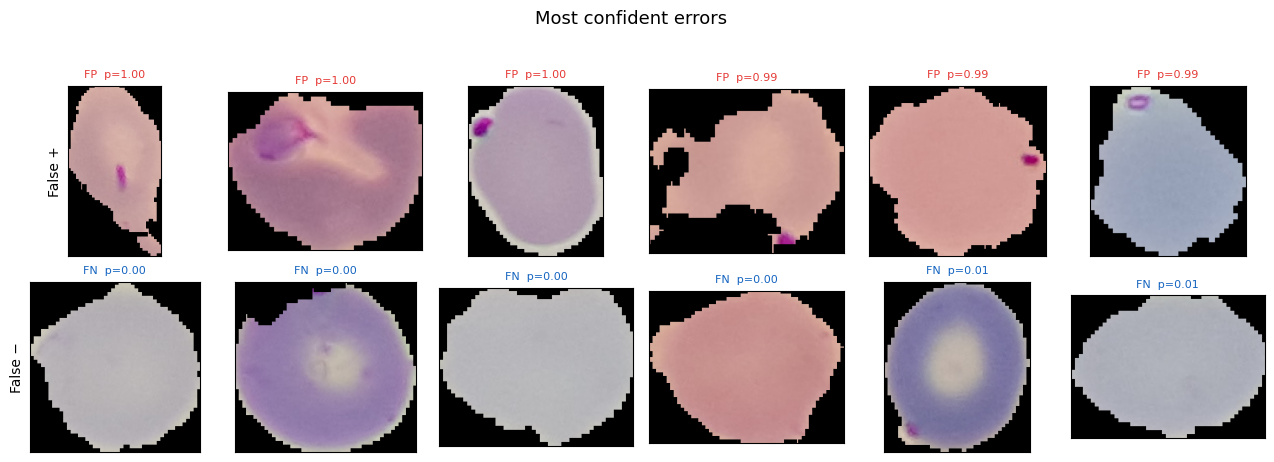

In [23]:
# ── Highest-confidence errors ──
fp = test_df[test_df.label == 0].nlargest(6, "prob")
fn = test_df[test_df.label == 1].nsmallest(6, "prob")

fig, axes = plt.subplots(2, 6, figsize=(13, 4.5))
for ax, (_, r) in zip(axes[0], fp.iterrows()):
    ax.imshow(Image.open(r.path))
    ax.set_title(f"FP  p={r.prob:.2f}", fontsize=8, color="#E53935")
    ax.set_xticks([]); ax.set_yticks([])
for ax, (_, r) in zip(axes[1], fn.iterrows()):
    ax.imshow(Image.open(r.path))
    ax.set_title(f"FN  p={r.prob:.2f}", fontsize=8, color="#1565C0")
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("False +", fontsize=10)
axes[1, 0].set_ylabel("False −", fontsize=10)
plt.suptitle("Most confident errors", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


## 8 · Light Hyper-parameter Sweep

Small grid over learning-rate × weight-decay, then a 3-seed stability check of the winner.


In [24]:
grid = [(1e-4, 1e-4), (3e-4, 1e-4), (3e-4, 1e-2), (1e-3, 1e-4)]
rows = []
for lr, wd in grid:
    print(f"\n── lr={lr}  wd={wd}")
    m, h = train_one(epochs=6, lr=lr, wd=wd, tag=f"lr{lr}_wd{wd}")
    pv = predict(m, loaders["val"])
    rows.append({"lr": lr, "wd": wd, "val_auc": float(roc_auc_score(splits["val"].label, pv))})
    del m; gc.collect(); torch.cuda.empty_cache()

tune_df = pd.DataFrame(rows).sort_values("val_auc", ascending=False)
best_lr, best_wd = float(tune_df.iloc[0]["lr"]), float(tune_df.iloc[0]["wd"])



── lr=0.0001  wd=0.0001
  ep 1/6  loss 0.1276  val AUC 0.9900  (62.2s)
  ep 2/6  loss 0.0860  val AUC 0.9913  (62.2s)
  ep 3/6  loss 0.0750  val AUC 0.9924  (62.2s)
  ep 4/6  loss 0.0583  val AUC 0.9917  (62.9s)
  ep 5/6  loss 0.0484  val AUC 0.9919  (62.3s)
  ep 6/6  loss 0.0402  val AUC 0.9931  (62.1s)
best val AUC 0.9931 → resnet18_lr0.0001_wd0.0001.pt

── lr=0.0003  wd=0.0001
  ep 1/6  loss 0.1296  val AUC 0.9912  (62.8s)
  ep 2/6  loss 0.0958  val AUC 0.9908  (62.2s)
  ep 3/6  loss 0.0842  val AUC 0.9922  (62.1s)
  ep 4/6  loss 0.0691  val AUC 0.9922  (62.4s)
  ep 5/6  loss 0.0577  val AUC 0.9922  (62.4s)
  ep 6/6  loss 0.0486  val AUC 0.9939  (62.2s)
best val AUC 0.9939 → resnet18_lr0.0003_wd0.0001.pt

── lr=0.0003  wd=0.01
  ep 1/6  loss 0.1299  val AUC 0.9909  (62.8s)
  ep 2/6  loss 0.0961  val AUC 0.9911  (62.2s)
  ep 3/6  loss 0.0845  val AUC 0.9924  (62.2s)
  ep 4/6  loss 0.0681  val AUC 0.9923  (61.9s)
  ep 5/6  loss 0.0584  val AUC 0.9927  (62.0s)
  ep 6/6  loss 0.0488  v

In [25]:
# Interactive heatmap of the grid
pivot = tune_df.pivot(index="wd", columns="lr", values="val_auc")
fig = go.Figure(go.Heatmap(
    z=pivot.values,
    x=[f"{c:.0e}" for c in pivot.columns],
    y=[f"{r:.0e}" for r in pivot.index],
    text=np.round(pivot.values, 4), texttemplate="%{text}",
    colorscale="Viridis", colorbar_title="val AUC",
    hovertemplate="lr=%{x}<br>wd=%{y}<br>AUC=%{z:.4f}<extra></extra>",
))
fig.update_layout(
    template=PLOTLY_TEMPLATE, height=320, width=480,
    title="Validation AUC heatmap (lr × wd)",
    xaxis_title="learning rate", yaxis_title="weight decay",
)
fig.show()
tune_df


,lr,wd,val_auc
2,0.0003,0.0100,0.994107
1,0.0003,0.0001,0.993876
0,0.0001,0.0001,0.993130
3,0.0010,0.0001,0.992775


In [26]:
# 3-seed re-run
seed_rows = []
for s in (0, 1, 2):
    set_seed(s)
    m, _ = train_one(epochs=8, lr=best_lr, wd=best_wd, tag=f"seed{s}")
    pt_s = predict(m, loaders["test"])
    seed_rows.append({"seed": s, **metrics(yt, pt_s)})
    del m; gc.collect(); torch.cuda.empty_cache()

seed_df = pd.DataFrame(seed_rows)

fig = go.Figure()
for col, color in [("AUC", "#E53935"), ("Acc", "#42A5F5"), ("F1", "#66BB6A")]:
    fig.add_trace(go.Bar(
        x=seed_df.seed.astype(str), y=seed_df[col], name=col,
        marker_color=color, text=seed_df[col].round(3), textposition="outside",
    ))
fig.update_layout(
    template=PLOTLY_TEMPLATE, barmode="group", height=380,
    title=f"3-seed stability  (mean AUC {seed_df.AUC.mean():.4f} ± {seed_df.AUC.std():.4f})",
    xaxis_title="seed", yaxis=dict(title="score", range=[0.85, 1.0]),
    legend=dict(orientation="h", y=1.1),
)
fig.show()


  ep 1/8  loss 0.1296  val AUC 0.9916  (61.8s)
  ep 2/8  loss 0.0960  val AUC 0.9911  (61.7s)
  ep 3/8  loss 0.0868  val AUC 0.9916  (62.0s)
  ep 4/8  loss 0.0732  val AUC 0.9911  (61.7s)
  ep 5/8  loss 0.0661  val AUC 0.9924  (61.4s)
  ep 6/8  loss 0.0560  val AUC 0.9933  (61.6s)
  ep 7/8  loss 0.0430  val AUC 0.9941  (62.9s)
  ep 8/8  loss 0.0366  val AUC 0.9941  (63.1s)
best val AUC 0.9941 → resnet18_seed0.pt
  ep 1/8  loss 0.1293  val AUC 0.9909  (63.7s)
  ep 2/8  loss 0.0968  val AUC 0.9914  (63.9s)
  ep 3/8  loss 0.0858  val AUC 0.9910  (62.7s)
  ep 4/8  loss 0.0738  val AUC 0.9922  (62.8s)
  ep 5/8  loss 0.0660  val AUC 0.9923  (63.6s)
  ep 6/8  loss 0.0567  val AUC 0.9940  (63.8s)
  ep 7/8  loss 0.0440  val AUC 0.9941  (63.9s)
  ep 8/8  loss 0.0371  val AUC 0.9942  (63.7s)
best val AUC 0.9942 → resnet18_seed1.pt
  ep 1/8  loss 0.1293  val AUC 0.9916  (63.4s)
  ep 2/8  loss 0.0952  val AUC 0.9914  (63.5s)
  ep 3/8  loss 0.0867  val AUC 0.9915  (63.0s)
  ep 4/8  loss 0.0734  val 

## 9 · Hardening

1. Export weights as **safetensors** + SHA-256  
2. Background-fraction gate (reject images unlike training cells)  
3. Strict upload validator (format · size · decompression-bomb · pixel re-encode)


In [27]:
from safetensors.torch import save_file, load_file

model = make_model()
model.load_state_dict(torch.load(BASE / "resnet18_seed0.pt", map_location="cpu"))
model.eval()

w_path = ART / "resnet18_malaria.safetensors"
save_file(model.state_dict(), str(w_path))
digest = hashlib.sha256(w_path.read_bytes()).hexdigest()
(ART / "resnet18_malaria.sha256").write_text(f"{digest}  resnet18_malaria.safetensors\n")
print(f"saved {w_path.name}  ·  sha256={digest[:20]}…")


saved resnet18_malaria.safetensors  ·  sha256=f47a66a52454930294c3…


In [28]:
def bg_fraction(arr):
    return (arr.max(axis=3) <= 10).mean(axis=(1, 2))

sample = splits["train"].sample(min(4000, len(splits["train"])), random_state=SEED)
arrs = np.stack([
    np.asarray(Image.open(p).convert("RGB").resize((IMG, IMG)))
    for p in sample.path
])
bg = bg_fraction(arrs)
lo, hi = float(np.percentile(bg, 1)), float(np.percentile(bg, 99.5))
gate = {"bg_lo": round(lo, 4), "bg_hi": round(hi, 4)}
(ART / "gate.json").write_text(json.dumps(gate, indent=2))

# Visualise the gate
fig = go.Figure()
fig.add_trace(go.Histogram(x=bg, nbinsx=40, marker_color="#5C6BC0", name="train cells"))
fig.add_vline(x=lo, line_dash="dash", line_color="#E53935",
              annotation_text=f"1st pct {lo:.3f}")
fig.add_vline(x=hi, line_dash="dash", line_color="#E53935",
              annotation_text=f"99.5th pct {hi:.3f}", annotation_position="top left")
fig.update_layout(
    template=PLOTLY_TEMPLATE, height=340,
    title="Background-fraction distribution (training cells)",
    xaxis_title="dark-background fraction", yaxis_title="count",
)
fig.show()
print("gate:", gate)


gate: {'bg_lo': 0.1798, 'bg_hi': 0.5085}


In [29]:
MAX_BYTES, MIN_SIDE, MAX_SIDE = 5 * 1024 * 1024, 32, 4096
ALLOWED = {"PNG", "JPEG"}
THRESHOLD = 0.5
REFER_BAND = (0.20, 0.80)

class UploadError(Exception):
    pass

def load_upload(raw: bytes) -> Image.Image:
    if not raw:
        raise UploadError("empty upload")
    if len(raw) > MAX_BYTES:
        raise UploadError("file too large (>5 MB)")
    old = Image.MAX_IMAGE_PIXELS
    Image.MAX_IMAGE_PIXELS = MAX_SIDE * MAX_SIDE
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error", Image.DecompressionBombWarning)
            with Image.open(io.BytesIO(raw)) as im:
                if im.format not in ALLOWED:
                    raise UploadError(f"unsupported format: {im.format}")
                w, h = im.size
                if not (MIN_SIDE <= w <= MAX_SIDE and MIN_SIDE <= h <= MAX_SIDE):
                    raise UploadError(f"size {w}x{h} out of range")
                im.verify()
            with Image.open(io.BytesIO(raw)) as im:
                rgb = im.convert("RGB")
            return Image.frombytes("RGB", rgb.size, rgb.tobytes())
    except UploadError:
        raise
    except Exception as e:
        raise UploadError(f"could not decode ({type(e).__name__})") from None
    finally:
        Image.MAX_IMAGE_PIXELS = old

@torch.no_grad()
def predict_bytes(raw: bytes, model, gate) -> dict:
    try:
        im = load_upload(raw)
    except UploadError as e:
        return {"status": "rejected", "reason": str(e)}
    a = np.asarray(im.resize((IMG, IMG), Image.BILINEAR), dtype=np.uint8)
    bg = float((a.max(axis=2) <= 10).mean())
    if not (gate["bg_lo"] <= bg <= gate["bg_hi"]):
        return {"status": "withheld", "background_fraction": round(bg, 3),
                "reason": f"bg fraction {bg:.3f} outside training range"}
    x = torch.from_numpy(a.copy()).permute(2, 0, 1).float().div(255)
    x = (x - torch.tensor(MEAN).view(3, 1, 1)) / torch.tensor(STD).view(3, 1, 1)
    p = float(torch.sigmoid(model(x.unsqueeze(0).to(device)).squeeze(1)))
    return {
        "status": "ok",
        "p_parasitized": round(p, 4),
        "label": "parasitized" if p >= THRESHOLD else "uninfected",
        "refer_to_human": REFER_BAND[0] < p < REFER_BAND[1],
        "background_fraction": round(bg, 3),
    }

# Smoke tests
raw_ok = open(splits["test"].path.iloc[0], "rb").read()
print("real cell →", predict_bytes(raw_ok, model, gate))
print("garbage  →", predict_bytes(b"not an image", model, gate))


real cell → {'status': 'ok', 'p_parasitized': 1.0, 'label': 'parasitized', 'refer_to_human': False, 'background_fraction': 0.234}
garbage  → {'status': 'rejected', 'reason': 'could not decode (UnidentifiedImageError)'}


## 10 · Calibration & Abstention

Reliability diagram and abstention bands.  
When the score sits near 0.5 the demo can refer the case to a human.


In [30]:
def reliability(p, y, n=10):
    bins = np.linspace(0, 1, n + 1)
    ece, pts = 0.0, []
    for i in range(n):
        m = (p >= bins[i]) & (p < bins[i + 1] if i < n - 1 else p <= bins[i + 1])
        if m.any():
            conf, acc = float(p[m].mean()), float(y[m].mean())
            ece += float(m.mean()) * abs(acc - conf)
            pts.append((conf, acc, int(m.sum())))
    return ece, pts

pv = predict(model, loaders["val"])
yv = splits["val"].label.values.astype(float)

fig = go.Figure()
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines",
                         line=dict(color="gray", dash="dot"), showlegend=False))

for name, p, y, color in [("val", pv, yv, "#42A5F5"), ("test", pt, yt.astype(float), "#E53935")]:
    ece, pts = reliability(p, y)
    fig.add_trace(go.Scatter(
        x=[a for a, *_ in pts], y=[b for _, b, _ in pts],
        mode="lines+markers", name=f"{name}  ECE={ece:.3f}",
        line=dict(color=color, width=2), marker=dict(size=8),
        hovertemplate="conf=%{x:.2f}<br>acc=%{y:.2f}<extra></extra>",
    ))

fig.update_layout(
    template=PLOTLY_TEMPLATE, height=420, width=480,
    title="Reliability diagram",
    xaxis_title="mean predicted P", yaxis_title="observed fraction",
    legend=dict(orientation="h", y=1.1),
    xaxis=dict(range=[0, 1]), yaxis=dict(range=[0, 1]),
)
fig.show()
fig.write_image  # noop if kaleido missing
try:
    import plotly.io as pio
    pio.write_image(fig, str(ART / "reliability.png"), scale=2)
except Exception:
    pass


In [31]:
# Export artefacts
from safetensors.torch import save_file
save_file(model.state_dict(), str(ART / "resnet18_malaria.safetensors"))
# ... sha256 + gate.json
print("Copy these files into your GitHub repo/model/ folder:")
print(list(ART.glob("*")))

Copy these files into your GitHub repo/model/ folder:
[PosixPath('/content/drive/MyDrive/malaria/repo_artifacts/resnet18_malaria.safetensors'), PosixPath('/content/drive/MyDrive/malaria/repo_artifacts/resnet18_malaria.sha256'), PosixPath('/content/drive/MyDrive/malaria/repo_artifacts/gate.json')]
